# Умная теплица: распределённая микроконтроллерная система
### Рабочий ноутбук проекта: описание, запуск, проверка и анализ данных

Три виртуальных ESP32 (`gh-soil-01`, `gh-tank-01`, `gh-climate-01`) измеряют и регулируют параметры теплицы, обмениваются
данными по MQTT с backend, который хранит телеметрию, применяет правила и отдаёт API. Ноутбук **выполняет работу целиком
внутри Python**, без Docker и Wokwi: прогоняет систему на симуляторе (те же JSON-сообщения проходят через настоящий код
backend), проверяет протокол по логам настоящих прошивок, запускает автотесты и анализирует полученные данные.

| Часть | Что делает |
|---|---|
| A | описание системы, протокола и правил |
| B | запуск системы на 72 часа симуляции, 9 сценариев |
| C | проверка протокола по логам прошивок |
| D | автоматические тесты |
| E | анализ данных (качество, полив, частота, связь, инциденты, аномалии) |
| F | демонстрация REST API |
| G | что нужно запустить вручную (Docker, Wokwi) |

**Как запускать:** `jupyter notebook notebooks/analysis.ipynb` → *Kernel → Restart & Run All* (около минуты).
Нужны `pandas numpy matplotlib scikit-learn scipy`; для части F дополнительно `pip install -r backend/requirements-dev.txt`.

In [1]:
import os, sys, json, time, subprocess, shutil, tempfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})

ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
assert os.path.exists(os.path.join(ROOT, "docker-compose.yml")), "Запустите ноутбук из корня проекта или из папки notebooks/"
for p in (ROOT, os.path.join(ROOT, "backend")):
    if p not in sys.path:
        sys.path.insert(0, p)
DATA = os.path.join(ROOT, "data")
print("корень проекта:", ROOT)

корень проекта: /mnt/attach/outputs/smart-greenhouse


# Часть A. Система, протокол и правила

**Узлы и датчики.** Новые по сравнению с семинаром датчики: влажность почвы, ультразвуковой HC-SR04, NTC-термистор,
фоторезистор. Исполнители: реле насоса, сервопривод форточки, досветка, зуммер.

| Узел | Измеряет | Управляет | Локальная автоматика |
|---|---|---|---|
| `gh-soil-01` | влажность почвы | насос | вкл. при < 30 %, выкл. при ≥ 60 %, защита насоса по времени |
| `gh-tank-01` | уровень воды (HC-SR04) | зуммер, светодиод | состояния ок / мало (≤ 25 %) / критично (≤ 10 %) с гистерезисом |
| `gh-climate-01` | температура, освещённость | форточка, досветка | форточка > 28 °C, досветка < 200 lux |

**Протокол.** MQTT, JSON v1, топики `<root>/<dev>/{telemetry,status,event,cmd,cmd/ack,config,config/ack}`.
Каждая телеметрия несёт `ts` (время измерения, мс), `boot` (идентификатор запуска) и `seq` (номер без пропусков),
команды подтверждаются по `cmd_id`, конфигурация версионируется (`cfg_ver`). Полное описание: `docs/PROTOCOL.md`.

**Надёжность.** Last Will + heartbeat, кольцевой буфер на 24 сообщения при обрыве, безопасный режим узла,
watchdog backend с автоперезагрузкой (не более 3 раз в час), повтор конфигурации при расхождении `cfg_ver`.

**Правила backend.** Блокировка насоса при критическом уровне воды; неэффективный полив → отказ насоса;
жара → автоматическое открытие форточки; заморозки; утечка; «залипший» датчик; аномалии (EWMA z-score).

# Часть B. Запуск системы на симуляторе (72 часа)

`Harness` соединяет модель трёх узлов с **настоящим** `GreenhouseService` (тем же, что работает за MQTT и базой данных).
Сообщения проходят через те же парсеры, детекторы и правила. Сценарии: настройка через конфигурацию, команды оператора,
шум и «залипание» датчика, отказ датчика уровня, утечка, жара, обрывы связи, отказ насоса.

In [2]:
from simulator.make_dataset import Harness, add_scenarios, ALL, export

t0 = time.time()
harness = h = Harness(seed=7)  # harness нужен для части F, h не трогать
add_scenarios(h, ALL)
h.run(72)
print(f"симуляция 72 ч выполнена за {time.time() - t0:.0f} с")
print("измерений:", len(h.st.telemetry), "| событий:", len(h.st.events), "| команд:", len(h.st.commands))
print("сценарии:", ", ".join(ALL))

симуляция 72 ч выполнена за 7 с
измерений: 15710 | событий: 48 | команд: 3
сценарии: config, operator, sensor_noise, tank_fault, leak, heat, outage, stuck, no_water


In [3]:
# воспроизводимость: заново полученные данные должны совпасть с файлами в data/ побайтно
tmp = tempfile.mkdtemp()
export(h, tmp)
md5 = lambda p: hashlib.md5(open(p, "rb").read()).hexdigest()
same = {f: md5(os.path.join(tmp, f)) == md5(os.path.join(DATA, f)) for f in ("telemetry.csv", "events.csv", "commands.csv")}
print(same)
assert all(same.values()), "данные расходятся с data/"

{'telemetry.csv': True, 'events.csv': True, 'commands.csv': True}


# Часть C. Протокол на логах настоящих прошивок

Скетчи трёх узлов собраны на обычном компьютере (g++, заглушки Arduino/WiFi/MQTT) и выполнены в сценариях; их MQTT-обмен
записан в `backend/tests/fixtures/*.log`. Ниже — какие сообщения публикуют узлы, и по одному примеру каждого типа.

In [4]:
fx = os.path.join(ROOT, "backend", "tests", "fixtures")
rows, samples = [], {}
for fn in sorted(os.listdir(fx)):
    if not fn.endswith(".log"):
        continue
    for line in open(os.path.join(fx, fn), encoding="utf-8"):
        p = line.rstrip("\n").split("\t")
        if p[0] == "PUB":
            kind = "/".join(p[1].split("/")[3:])
            rows.append({"узел": fn[:-4], "тип": kind})
            samples.setdefault(kind, p[-1])
pub = pd.DataFrame(rows)
print("публикаций в логах:", len(pub))
pub.groupby(["узел", "тип"]).size().unstack(fill_value=0)

публикаций в логах: 109


тип,cmd/ack,config/ack,event,status,telemetry
узел,,,,,
gh-climate-01,1,0,0,3,8
gh-soil-01,6,2,1,12,56
gh-tank-01,1,0,7,3,9


In [5]:
for kind, payload in sorted(samples.items()):
    print(f"--- {kind}")
    print(json.dumps(json.loads(payload), ensure_ascii=False)[:300])

--- cmd/ack
{"v": 1, "dev": "gh-climate-01", "cmd_id": "v1", "status": "ok", "reason": ""}
--- config/ack
{"v": 1, "dev": "gh-soil-01", "cfg_ver": 5, "status": "ok"}
--- event
{"v": 1, "dev": "gh-soil-01", "boot": 3969145544, "ts": 1793736345796, "type": "link_restored", "sev": "info", "msg": "link restored: outage_s=32 buffered=13"}
--- status
{"v": 1, "dev": "gh-climate-01", "type": "climate", "fw": "1.0.0", "state": "online", "boot": 3969145544, "up": 0, "rssi": -55, "heap": 200000, "buf_n": 0, "cfg_ver": 0}
--- telemetry
{"v": 1, "dev": "gh-climate-01", "type": "climate", "boot": 3969145544, "seq": 1, "ts": 1793736346456, "up": 200, "buf": 0, "drop": 0, "mode": "auto", "itv": 2000, "rssi": -55, "m": {"temperature_c": 150.0, "light_lux": 100000, "vent_open": 1, "grow_light_on": 0, "override": 0}}


# Часть D. Автоматические проверки

Тесты backend (протокол, детекторы, правила, контракт с прошивками, замкнутый цикл на 72 часа) и хост-тесты прошивок.

In [6]:
t0 = time.time()
r = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
                   cwd=os.path.join(ROOT, "backend"), capture_output=True, text=True)
out = (r.stdout + r.stderr).strip().splitlines()
print("\n".join(out[-5:]))
print(f"код возврата: {r.returncode}, время: {time.time() - t0:.0f} с")
assert r.returncode == 0

sssss.....................................
----------------------------------------------------------------------
Ran 42 tests in 12.922s

OK (skipped=5)
код возврата: 0, время: 14 с


In [7]:
# хост-тесты прошивок: нужен g++ и bash (Linux/macOS; на Windows - WSL или Git Bash)
if shutil.which("g++") and shutil.which("bash"):
    r = subprocess.run(["bash", "firmware/tests/run_tests.sh"], cwd=ROOT, capture_output=True, text=True)
    print("\n".join((r.stdout + r.stderr).strip().splitlines()[-8:]))
    assert r.returncode == 0
else:
    print("g++/bash не найдены - пропуск. Запустите вручную: bash firmware/tests/run_tests.sh")

test_logic: ALL OK
built+ran gh-soil-01
built+ran gh-tank-01
built+ran gh-climate-01
soil OK: 56 сообщений, буферизовано 14, ack=6
tank OK: 9 сообщений
climate OK: 8 сообщений
ALL FIRMWARE HOST CHECKS PASSED


# Часть E. Анализ данных

Данные: 72 часа работы трёх узлов (результат части B, сохранён в `data/`). Разделы: качество данных и целостность
последовательностей; динамика процессов; эффективность полива; адаптивная частота; связь и буферизация; инциденты;
аномалии (IsolationForest против правил backend); суточная сводка; выводы.

In [8]:
tel = pd.read_csv(os.path.join(DATA, "telemetry.csv"), parse_dates=["ts"])
ev  = pd.read_csv(os.path.join(DATA, "events.csv"), parse_dates=["ts"])
cmd = pd.read_csv(os.path.join(DATA, "commands.csv"), parse_dates=["ts"])
print("telemetry:", tel.shape, "| events:", ev.shape, "| commands:", cmd.shape)
print("период:", tel.ts.min(), "->", tel.ts.max())
tel.head()

telemetry: (15710, 20) | events: (48, 5) | commands: (3, 8)
период: 2026-10-30 00:00:01+00:00 -> 2026-11-02 00:00:00+00:00


,ts,device_id,boot,seq,buffered,distance_cm,grow_light_on,level_pct,light_lux,muted,override,pump_cooldown,pump_locked,pump_on,sensor_ok,soil_moisture_pct,soil_raw,tank_state,temperature_c,vent_open
0,2026-10-30 00:00:01+00:00,gh-climate-01,1003,1,0,NaN,1.0,NaN,1.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.0,0.0
1,2026-10-30 00:00:01+00:00,gh-soil-01,1001,1,0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN,47.9,1961.0,NaN,NaN,NaN
2,2026-10-30 00:00:01+00:00,gh-tank-01,1002,1,0,14.8,NaN,85.2,NaN,0.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,NaN,NaN
3,2026-10-30 00:00:06+00:00,gh-climate-01,1003,2,0,NaN,1.0,NaN,143.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.0,0.0
4,2026-10-30 00:00:06+00:00,gh-soil-01,1001,2,0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,NaN,48.1,1969.0,NaN,NaN,NaN


## E1. Качество данных и целостность последовательностей

In [9]:
g = tel.groupby("device_id")
q = pd.DataFrame({
    "строк": g.size(),
    "буферизованных": g.buffered.sum(),
    "доля буфера, %": (g.buffered.mean() * 100).round(2),
    "перезагрузок (boot)": g.boot.nunique() - 1,
})
# пропуски seq внутри одного boot-цикла: должно быть 0, если буферизация и повторная отправка работают
def gaps(df):
    lost = 0
    for _, b in df.groupby("boot"):
        s = np.sort(b.seq.values)
        lost += int((np.diff(s) - 1).clip(min=0).sum())
    return lost
q["потерянных seq"] = g.apply(gaps, include_groups=False)
q["дубликатов seq"] = g.apply(lambda d: int(d.duplicated(["boot", "seq"]).sum()), include_groups=False)
q

,строк,буферизованных,"доля буфера, %",перезагрузок (boot),потерянных seq,дубликатов seq
device_id,,,,,,
gh-climate-01,4336,12,0.28,0,0,0
gh-soil-01,4493,4,0.09,0,0,0
gh-tank-01,6881,0,0.00,0,0,0


In [10]:
# доля пропусков по метрикам (NaN нормальны: каждый узел присылает только свои метрики)
miss = tel.drop(columns=["ts", "device_id", "boot", "seq", "buffered"]).isna().groupby(tel.device_id).mean().round(2)
miss.loc[:, (miss < 1).any()]

,distance_cm,grow_light_on,level_pct,light_lux,muted,override,pump_cooldown,pump_locked,pump_on,sensor_ok,soil_moisture_pct,soil_raw,tank_state,temperature_c,vent_open
device_id,,,,,,,,,,,,,,,
gh-climate-01,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
gh-soil-01,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0
gh-tank-01,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0


## E2. Динамика процессов

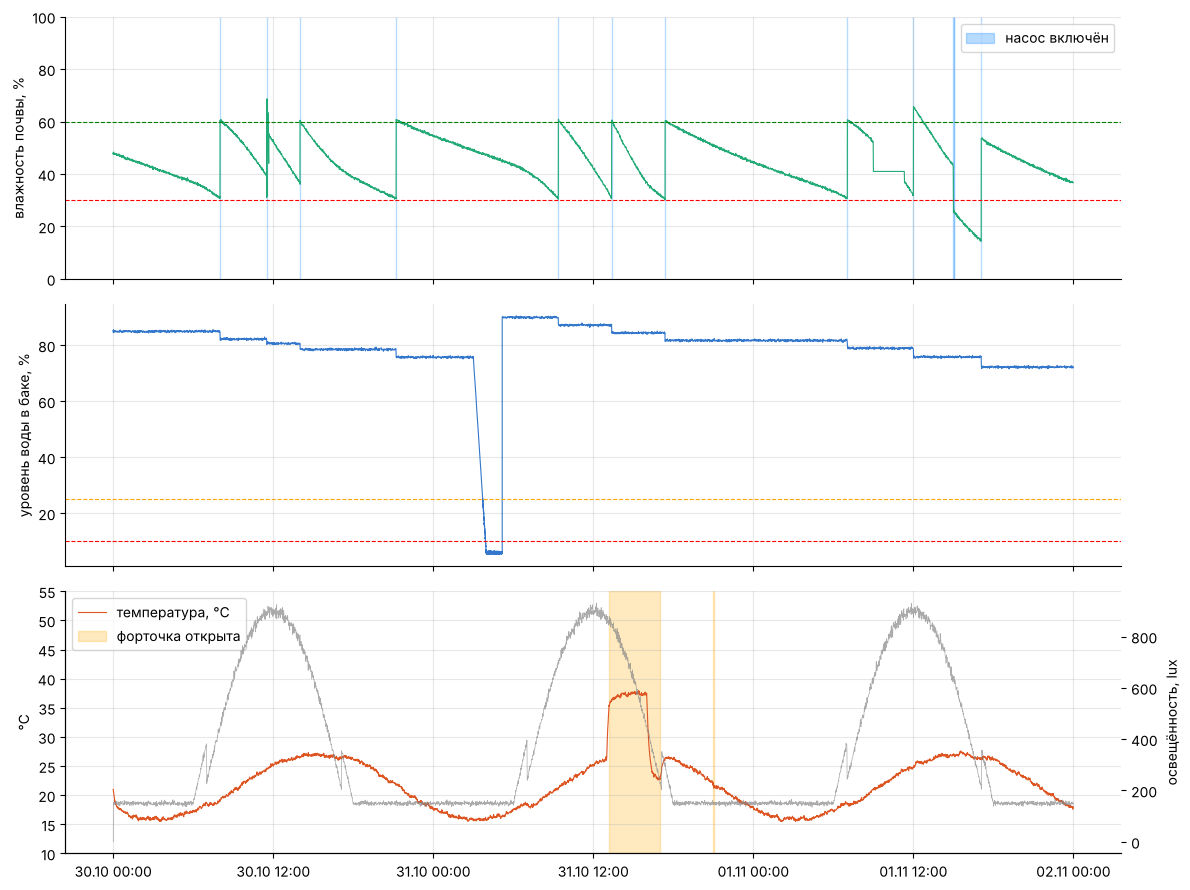

In [11]:
soil = tel[tel.device_id == "gh-soil-01"].set_index("ts").sort_index()
tank = tel[tel.device_id == "gh-tank-01"].set_index("ts").sort_index()
clim = tel[tel.device_id == "gh-climate-01"].set_index("ts").sort_index()

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(soil.index, soil.soil_moisture_pct, lw=.8, color="#2a7")
ax[0].fill_between(soil.index, 0, 100, where=soil.pump_on == 1, color="#39f", alpha=.35, step="post", label="насос включён")
ax[0].axhline(30, ls="--", c="r", lw=.8); ax[0].axhline(60, ls="--", c="g", lw=.8)
ax[0].set_ylabel("влажность почвы, %"); ax[0].set_ylim(0, 100); ax[0].legend(loc="upper right")
ax[1].plot(tank.index, tank.level_pct.where(tank.level_pct >= 0), lw=.8, color="#37c")  # -1 = ошибка датчика
ax[1].axhline(25, ls="--", c="orange", lw=.8); ax[1].axhline(10, ls="--", c="r", lw=.8)
ax[1].set_ylabel("уровень воды в баке, %")
ax[2].plot(clim.index, clim.temperature_c, lw=.8, color="#d52", label="температура, °C")
ax[2].fill_between(clim.index, 10, 55, where=clim.vent_open == 1, color="#fa0", alpha=.25, step="post", label="форточка открыта")
ax[2].set_ylabel("°C"); ax[2].set_ylim(10, 55)
a2 = ax[2].twinx(); a2.plot(clim.index, clim.light_lux, lw=.5, color="#888", alpha=.7); a2.set_ylabel("освещённость, lux"); a2.grid(False)
ax[2].legend(loc="upper left")
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
fig.tight_layout(); plt.show()

## E3. Эффективность полива
Для каждого включения насоса считаем прирост влажности и длительность.

In [12]:
s = soil[["soil_moisture_pct", "pump_on"]].copy()
s["run"] = (s.pump_on.diff().fillna(0) == 1).cumsum() * (s.pump_on == 1)
runs = []
for rid, d in s[s.run > 0].groupby("run"):
    before = s.soil_moisture_pct[:d.index[0]].tail(3).mean()
    after = s.soil_moisture_pct[d.index[-1]:].head(5).max()
    runs.append({"начало": d.index[0], "длит., с": (d.index[-1] - d.index[0]).total_seconds(),
                 "до, %": round(before, 1), "после, %": round(after, 1), "прирост, %": round(after - before, 1)})
runs = pd.DataFrame(runs)
print("поливов:", len(runs), "| средний прирост:", round(runs["прирост, %"].mean(), 1), "%")
runs.head(15)

поливов: 13 | средний прирост: 22.9 %


,начало,"длит., с","до, %","после, %","прирост, %"
0,2026-10-30 08:00:06+00:00,22.0,31.0,60.5,29.5
1,2026-10-30 11:30:20+00:00,12.0,36.9,68.7,31.8
2,2026-10-30 14:00:01+00:00,16.0,36.6,60.5,23.9
3,2026-10-30 21:12:34+00:00,22.0,30.8,60.8,30.0
4,2026-10-31 09:22:20+00:00,22.0,30.6,60.9,30.3
5,2026-10-31 13:22:01+00:00,22.0,30.8,60.6,29.8
6,2026-10-31 17:22:36+00:00,22.0,30.2,60.4,30.2
7,2026-11-01 07:02:44+00:00,22.0,30.7,60.7,30.0
8,2026-11-01 12:00:01+00:00,24.0,32.1,65.8,33.7
9,2026-11-01 15:00:00+00:00,28.0,37.3,26.2,-11.1


In [13]:
# неэффективные поливы (прирост < 3 п.п.) - кандидаты на отказ насоса / пустую магистраль
bad = runs[runs["прирост, %"] < 3]
print("неэффективных:", len(bad)); bad

неэффективных: 3


,начало,"длит., с","до, %","после, %","прирост, %"
9,2026-11-01 15:00:00+00:00,28.0,37.3,26.2,-11.1
10,2026-11-01 15:00:50+00:00,28.0,25.9,25.9,-0.0
11,2026-11-01 15:01:40+00:00,28.0,25.7,25.9,0.2


## E4. Адаптивная частота телеметрии
Узел переходит на более частые измерения во время активных процессов (полив, тревога по баку, быстрая смена температуры).

                count  min   25%   50%   75%    max
device_id                                          
gh-climate-01  4323.0  1.0  60.0  60.0  60.0  780.0
gh-soil-01     4488.0  1.0  60.0  60.0  60.0  300.0
gh-tank-01     6880.0  1.0   2.0  60.0  60.0   60.0


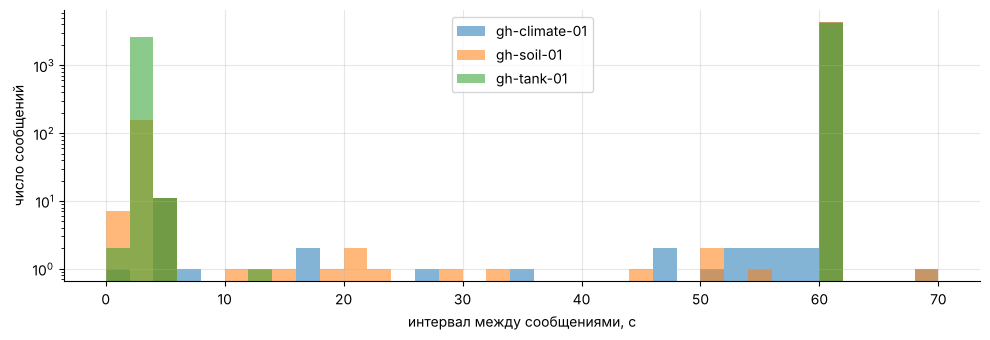

In [14]:
nb = tel[tel.buffered == 0].sort_values(["device_id", "ts"]).copy()
nb["dt"] = nb.groupby(["device_id", "boot"]).ts.diff().dt.total_seconds()
print(nb.groupby("device_id").dt.describe().round(1)[["count", "min", "25%", "50%", "75%", "max"]])
fig, ax = plt.subplots(figsize=(10, 3.5))
for dev, d in nb.groupby("device_id"):
    ax.hist(d.dt.clip(upper=70), bins=np.arange(0, 72, 2), alpha=.55, label=dev)
ax.set_xlabel("интервал между сообщениями, с"); ax.set_ylabel("число сообщений"); ax.set_yscale("log"); ax.legend()
fig.tight_layout(); plt.show()

## E5. Связь, буферизация и восстановление
При обрыве узел складывает сообщения в кольцевой буфер и после восстановления отправляет с флагом `buf=1` и исходными метками времени.

In [15]:
b = tel[tel.buffered == 1]
print("буферизованных сообщений:", len(b))
b.groupby("device_id").agg(первое=("ts", "min"), последнее=("ts", "max"), штук=("seq", "size"))

буферизованных сообщений: 16


,первое,последнее,штук
device_id,,,
gh-climate-01,2026-10-31 20:00:54+00:00,2026-10-31 20:11:54+00:00,12
gh-soil-01,2026-10-31 22:00:59+00:00,2026-10-31 22:03:59+00:00,4


In [16]:
off = ev[ev.type.isin(["device_offline", "device_online", "link_restored"])][["ts", "device_id", "type", "severity", "message"]]
off

,ts,device_id,type,severity,message
29,2026-10-31 20:00:22+00:00,gh-climate-01,device_offline,critical,connection lost (lwt)
30,2026-10-31 20:12:00+00:00,gh-climate-01,device_online,info,device is back online after 726 s
31,2026-10-31 20:12:00+00:00,gh-climate-01,link_restored,info,link restored: buffered=12
32,2026-10-31 22:00:22+00:00,gh-soil-01,device_offline,critical,connection lost (lwt)
33,2026-10-31 22:04:00+00:00,gh-soil-01,device_online,info,device is back online after 241 s
34,2026-10-31 22:04:00+00:00,gh-soil-01,link_restored,info,link restored: buffered=4


## E6. Инциденты

In [17]:
inc = ev[~ev.type.isin(["config_changed", "device_registered", "device_online"])]
print(inc.groupby(["severity", "type"]).size().to_string())
inc[inc.severity.isin(["critical", "warning"]) & (inc.type != "anomaly")][["ts", "device_id", "type", "severity", "message"]].reset_index(drop=True)

severity  type                  
critical  device_offline             2
          heat_alarm                 1
          leak_suspected             1
          pump_fault                 1
          pump_locked                1
          sensor_fault               1
          tank_state                 1
info      heat_cleared               1
          link_restored              2
          pump_unlocked              1
          sensor_recovered           1
          tank_state                 1
warning   anomaly                   12
          irrigation_ineffective     1
          pump_failsafe              4
          sensor_stuck               1
          tank_state                 1


,ts,device_id,type,severity,message
0,2026-10-30 20:00:00+00:00,gh-tank-01,sensor_fault,critical,HC-SR04: no echo (3 consecutive failures)
1,2026-10-31 03:06:56+00:00,gh-tank-01,leak_suspected,critical,tank level falls 0.8 %/min while pumps are idle - possible leak
2,2026-10-31 03:42:08+00:00,gh-tank-01,tank_state,warning,tank low
3,2026-10-31 03:54:29+00:00,gh-tank-01,tank_state,critical,tank critical
4,2026-10-31 03:54:41+00:00,gh-soil-01,pump_locked,critical,pump locked: tank level 10% <= 10%
5,2026-10-31 13:10:48+00:00,gh-climate-01,heat_alarm,critical,temperature 35.4 C >= 35 C
6,2026-10-31 20:00:22+00:00,gh-climate-01,device_offline,critical,connection lost (lwt)
7,2026-10-31 22:00:22+00:00,gh-soil-01,device_offline,critical,connection lost (lwt)
8,2026-11-01 10:59:07+00:00,gh-soil-01,sensor_stuck,warning,soil_moisture_pct did not change for 120 samples (sensor stuck?)
9,2026-11-01 15:00:30+00:00,gh-soil-01,pump_failsafe,warning,"max run time exceeded, pump stopped"


                       ts       cmd_id     device_id       cmd                args    source status  reason
2026-10-31 13:10:48+00:00 c-0000000002 gh-climate-01 vent_open {"duration_s": 300} rule:heat  acked     NaN


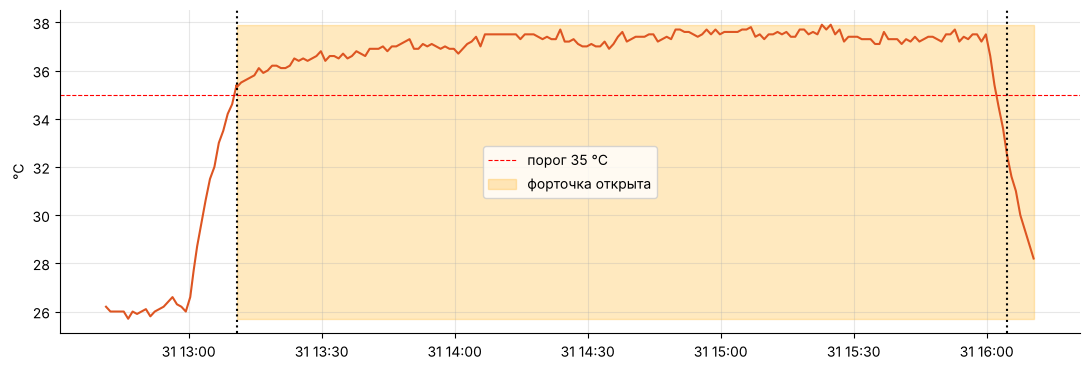

In [18]:
# жара: тревога backend и автоматическая команда vent_open
heat = ev[ev.type.isin(["heat_alarm", "heat_cleared"])]
t0 = heat.ts.iloc[0]
w = clim[t0 - pd.Timedelta("30min"): t0 + pd.Timedelta("3h")]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(w.index, w.temperature_c, color="#d52"); ax.axhline(35, ls="--", c="r", lw=.8, label="порог 35 °C")
ax.fill_between(w.index, w.temperature_c.min(), w.temperature_c.max(), where=w.vent_open == 1, color="#fa0", alpha=.25, step="post", label="форточка открыта")
for _, r in heat.iterrows(): ax.axvline(r.ts, c="k", ls=":")
ax.legend(); ax.set_ylabel("°C"); fig.tight_layout(); plt.show()
print(cmd[cmd.source.str.startswith("rule")].to_string(index=False))

событие leak_suspected: 2026-10-31 03:06:56+00:00
медианная скорость изменения уровня за все 72 ч: 0.00 %/ч
наклон в окне срабатывания правила: -72.05 %/ч -> прогноз до пустого бака: 0.5 ч


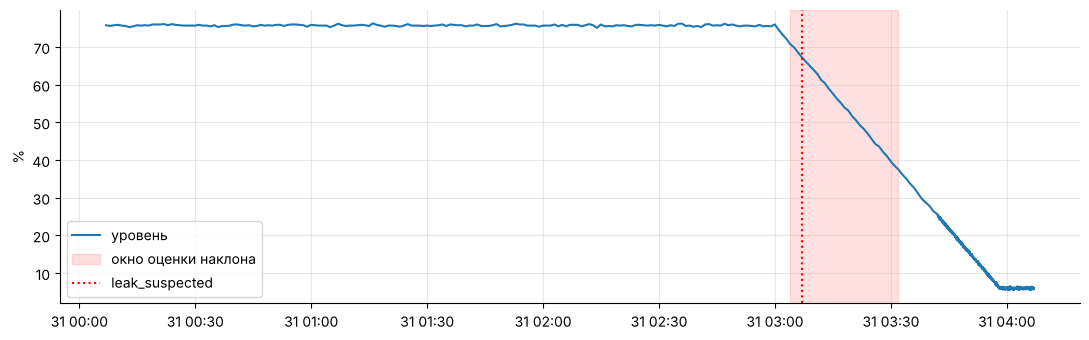

In [19]:
# утечка: скорость падения уровня в «обычное» время и в окне инцидента
lv = tank.level_pct.where(tank.level_pct >= 0)
rate = lv.diff() / tank.index.to_series().diff().dt.total_seconds() * 3600
leak_ev = ev[ev.type == "leak_suspected"].iloc[0]
full = lv[leak_ev.ts - pd.Timedelta("3h"): leak_ev.ts + pd.Timedelta("1h")]
win = lv[leak_ev.ts - pd.Timedelta("3min"): leak_ev.ts + pd.Timedelta("25min")]   # окно, на котором сработало правило
x = (win.index - win.index[0]).total_seconds() / 3600
slope, icpt = np.polyfit(x[win.notna()], win.dropna(), 1)
print(f"событие leak_suspected: {leak_ev.ts}")
print(f"медианная скорость изменения уровня за все 72 ч: {rate.median():.2f} %/ч")
print(f"наклон в окне срабатывания правила: {slope:.2f} %/ч -> прогноз до пустого бака: {max(win.dropna().iloc[-1], 0) / abs(slope):.1f} ч" if slope < 0 else "наклон положительный")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(full.index, full.values, label="уровень"); ax.axvspan(win.index[0], win.index[-1], color="r", alpha=.12, label="окно оценки наклона"); ax.axvline(leak_ev.ts, c="r", ls=":", label="leak_suspected")
ax.set_ylabel("%"); ax.legend(); fig.tight_layout(); plt.show()

## E6b. Обнаружение аномалий

Backend ловит аномалии онлайн правилами (EWMA z-score, «залипание» датчика, утечка). Сравним с офлайн-моделью
**IsolationForest** по признакам: скорость изменения влажности, остаток относительно скользящей медианы, скользящее СКО.
Интервалы работы насоса исключаем: резкий рост влажности при поливе - штатное поведение.

точек помечено IsolationForest: 9 из 4249
событий backend по почвенному узлу: 6


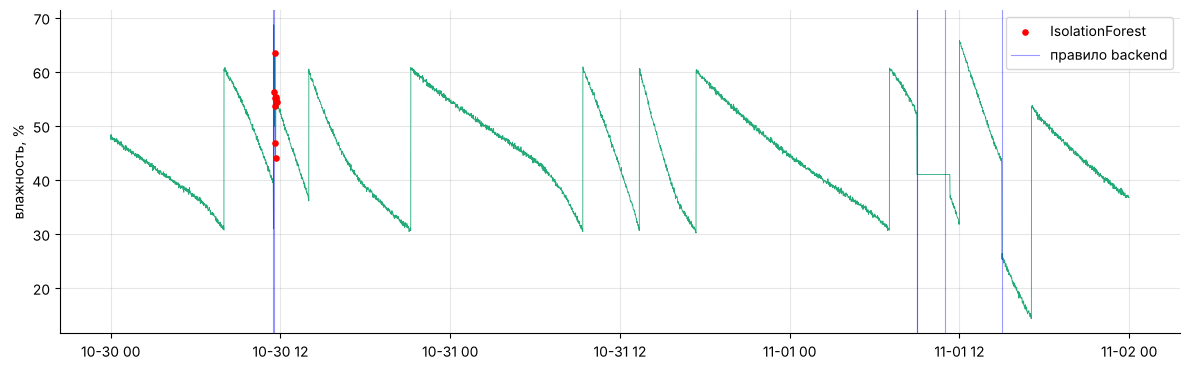

In [20]:
from sklearn.ensemble import IsolationForest
f = soil[["soil_moisture_pct", "pump_on"]].copy()
f["d1"] = f.soil_moisture_pct.diff()
f["res"] = f.soil_moisture_pct - f.soil_moisture_pct.rolling(15, center=True, min_periods=5).median()
f["std10"] = f.soil_moisture_pct.rolling(10, min_periods=5).std()
pump_zone = f.pump_on.rolling(8, center=True, min_periods=1).max() == 1
X = f[["d1", "res", "std10"]].dropna()
X = X[~pump_zone.reindex(X.index)]
iso = IsolationForest(n_estimators=200, contamination=0.002, random_state=7).fit(X)
f["iso"] = False
f.loc[X.index, "iso"] = iso.predict(X) == -1
print("точек помечено IsolationForest:", int(f.iso.sum()), "из", len(X))
rule = ev[(ev.device_id == "gh-soil-01") & (ev.type.isin(["anomaly", "sensor_stuck"]))]
print("событий backend по почвенному узлу:", len(rule))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(f.index, f.soil_moisture_pct, lw=.6, color="#2a7")
ax.scatter(f.index[f.iso], f.soil_moisture_pct[f.iso], s=14, c="r", label="IsolationForest", zorder=3)
for i, r in enumerate(rule.itertuples()): ax.axvline(r.ts, c="b", alpha=.4, lw=.8, label="правило backend" if i == 0 else None)
ax.legend(); ax.set_ylabel("влажность, %"); fig.tight_layout(); plt.show()

In [21]:
# согласие методов: какую долю правил-событий подтверждает офлайн-модель в окне ±5 минут
hits = 0
for r in rule.itertuples():
    near = f.iso[r.ts - pd.Timedelta("5min"): r.ts + pd.Timedelta("5min")]
    hits += int(near.any())
print(f"подтверждено офлайн-моделью: {hits} из {len(rule)}")

подтверждено офлайн-моделью: 2 из 6


## E7. Суточная сводка

In [22]:
day = pd.DataFrame({
    "влажность, ср.": soil.soil_moisture_pct.resample("1D").mean(),
    "поливов": (soil.pump_on.diff() == 1).resample("1D").sum(),
    "уровень бака, мин.": tank.level_pct.where(tank.level_pct >= 0).resample("1D").min(),
    "T макс, °C": clim.temperature_c.resample("1D").max(),
    "T мин, °C": clim.temperature_c.resample("1D").min(),
}).round(1).dropna(subset=["влажность, ср."])
day

,"влажность, ср.",поливов,"уровень бака, мин.","T макс, °C","T мин, °C"
ts,,,,,
2026-10-30 00:00:00+00:00,45.0,4.0,75.3,27.3,15.5
2026-10-31 00:00:00+00:00,46.8,3.0,5.4,37.9,15.5
2026-11-01 00:00:00+00:00,41.5,6.0,71.6,27.6,15.5


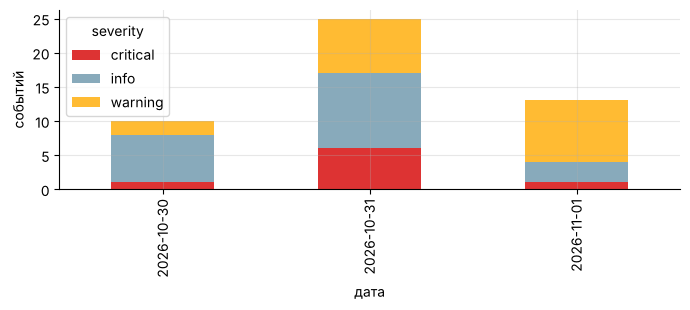

In [23]:
sev = ev.groupby([ev.ts.dt.date, "severity"]).size().unstack(fill_value=0)
sev.plot(kind="bar", stacked=True, figsize=(7, 3.2), color={"info": "#8ab", "warning": "#fb3", "critical": "#d33"})
plt.xlabel("дата"); plt.ylabel("событий"); plt.tight_layout(); plt.show()

## E8. Выводы

* Целостность: внутри каждого boot-цикла нет потерянных и дублированных `seq`, в том числе после обрывов связи -
  буфер и повторная отправка работают, а метки времени устройства сохраняются.
* Полив: типичный цикл поднимает влажность до верхнего порога гистерезиса; неэффективные поливы выявляются и
  эскалируются (`irrigation_ineffective` -> `pump_fault` -> блокировка насоса до решения оператора).
* Адаптивная частота: во время активных процессов интервал сокращается, в покое остаётся базовым - трафик экономится.
* Инциденты (жара, утечка, неисправность датчика уровня, «залипание», отключение узлов) обнаружены и описаны событиями;
  при перегреве backend сам отправил команду открытия форточки.
* Аномалии: офлайн-модель IsolationForest подтверждает часть срабатываний правил; различия объясняются тем, что правила
  работают онлайн и знают контекст (режим, состояние насоса), а модель видит только форму сигнала.
* Ограничения: данные синтетические (физическая модель + шум), поэтому пороги нужно перекалибровать на реальной теплице.

# Часть F. REST API (в процессе, без сервера)

Приложение FastAPI создаётся на том же `GreenhouseService`, в котором после симуляции лежат данные, и опрашивается
тестовым HTTP-клиентом. Так проверяются авторизация по `X-API-Key`, чтение данных, агрегаты и отправка команды.

In [24]:
try:
    from fastapi.testclient import TestClient
    from app.main import create_app
    from app.config import Settings
except ImportError as e:
    print("Часть F пропущена:", e)
    print("Установите зависимости: pip install -r backend/requirements-dev.txt  и запустите ячейку снова.")
else:
    client = TestClient(create_app(harness.svc, Settings(topic_root="gh-k7q2x9/greenhouse", api_key="demo", rate_limit_per_min=600)))
    H = {"X-API-Key": "demo"}
    print("без ключа:", client.get("/api/v1/devices").status_code, "| с ключом:", client.get("/api/v1/devices", headers=H).status_code)
    devs = client.get("/api/v1/devices", headers=H).json()
    print(pd.DataFrame([{k: d[k] for k in ("device_id", "type", "state", "cfg_ver")} for d in devs]))
    agg = client.get("/api/v1/devices/gh-climate-01/aggregate", params={"metric": "temperature_c", "bucket_s": 3600}, headers=H).json()
    print("агрегат температуры по часам (первые 3):", agg[:3] if isinstance(agg, list) else agg)
    r = client.post("/api/v1/devices/gh-soil-01/commands", json={"cmd": "pump_on", "duration_s": 10}, headers=H)
    print("команда pump_on:", r.status_code, r.json())
    print("health:", client.get("/health").json())

Часть F пропущена: No module named 'fastapi'
Установите зависимости: pip install -r backend/requirements-dev.txt  и запустите ячейку снова.


# Часть G. Что нужно запустить вручную

В ноутбуке выполнено всё, что возможно без внешних сервисов. Остальное запускается на вашем компьютере по
пошаговой инструкции **`docs/ИНСТРУКЦИЯ.md`**:

1. `docker compose up` — реальные брокер, база TimescaleDB, backend, Prometheus, Grafana (вариант с симулятором узлов);
2. три проекта Wokwi (`firmware/<узел>/`) — виртуальные ESP32 подключаются к тому же брокеру;
3. сохранить скриншоты Grafana и Wokwi для отчёта и защиты.

Эти шаги проверяют то, что симулятор заменяет: настоящую базу данных, брокер и скетчи на виртуальном железе.